# 1. Your first market

This tutorial runs a GLASS market, looks at what happened (prices, liquidity,
who made and lost money, liquidations) and shows what the agents are allowed
to see under each transparency level.

**Setup**: from the repository root, `pip install -e ".[analysis]"` (pandas and
matplotlib), then open this notebook with Jupyter. Every run is reproducible:
the same seed gives exactly the same market.

Contents:
1. Run a scenario
2. Prices and liquidity
3. Who made money
4. Statistical properties of returns
5. A volatile market: liquidations
6. What agents can see: transparency
7. Save, reload, replay, and the other tools

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glass_sim import PerpetualMarket, Side, Transparency, TransparencyError, parse_duration, scenarios

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (11, 3.5)

## 1. Run a scenario

A *scenario* is a complete `MarketConfig`: the contract, the index (spot)
price process, news, funding, liquidation rules, latency, the transparency
level and the population of scripted traders. `scenarios.default` is the
reference market: 88 agents of nine types under FULL transparency.

In [2]:
config = scenarios.default(seed=1, duration=parse_duration("2h"))
print(f"transparency: {config.transparency.value}, duration: {config.duration / 3600:.0f} h")
pd.DataFrame([{"type": spec.agent.__name__, "count": spec.count, "collateral": spec.collateral} for spec in config.agents])

transparency: full, duration: 2 h


,type,count,collateral
0,MarketMaker,3,"(300000.0, 600000.0)"
1,NoiseTrader,60,"(1000.0, 20000.0)"
2,MomentumTrader,8,"(20000.0, 80000.0)"
3,BasisArbitrageur,4,"(100000.0, 250000.0)"
4,InformedTrader,2,"(50000.0, 150000.0)"
5,Whale,1,"(1000000.0, 2000000.0)"
6,FlowFollower,3,"(20000.0, 60000.0)"
7,CopyTrader,6,"(5000.0, 30000.0)"
8,LiquidationHunter,1,"(200000.0, 400000.0)"


In [3]:
result = PerpetualMarket(config).run()
summary = result.summary()
keys = ["trades", "volume_contracts", "two_sided_book_fraction", "median_spread_bps",
        "last_index_mean_abs_bps", "return_vol_1m_bps", "liquidations", "fees_collected", "conservation_error"]
pd.Series({key: f"{summary[key]:,.6g}" for key in keys})

trades                            4,709
volume_contracts                602,131
two_sided_book_fraction        0.999861
median_spread_bps               10.9352
last_index_mean_abs_bps         10.5637
return_vol_1m_bps               27.9235
liquidations                          3
fees_collected                 36,180.2
conservation_error         -2.79397e-09
dtype: str

`conservation_error` is the accounting check: collateral, fees, funding,
penalties and the insurance fund always add up, so it should be zero up to
floating-point rounding. Every field is described in `docs/metrics.md`.

## 2. Prices and liquidity

`to_frames()` returns pandas DataFrames. `bars` has one row per simulated
second: OHLC of the trade price, the mark price (used for margin), the index
(the spot price the perpetual tracks) and the top of the book.

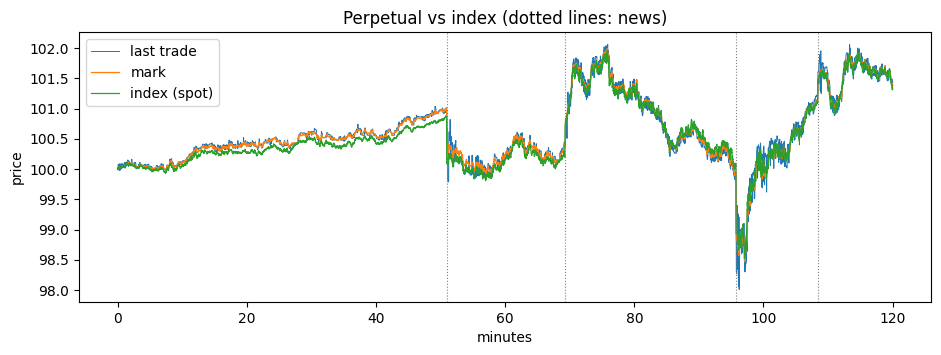

In [4]:
frames = result.to_frames()
bars = frames["bars"]
minutes = bars.index / 60

fig, ax = plt.subplots()
ax.plot(minutes, bars["close"], lw=0.7, label="last trade")
ax.plot(minutes, bars["mark"], lw=0.9, label="mark")
ax.plot(minutes, bars["index"], lw=0.9, label="index (spot)")
for t in frames["news"]["time"]:
    ax.axvline(t / 60, color="grey", ls=":", lw=0.8)
ax.set_xlabel("minutes"); ax.set_ylabel("price"); ax.legend(); ax.set_title("Perpetual vs index (dotted lines: news)")
plt.show()

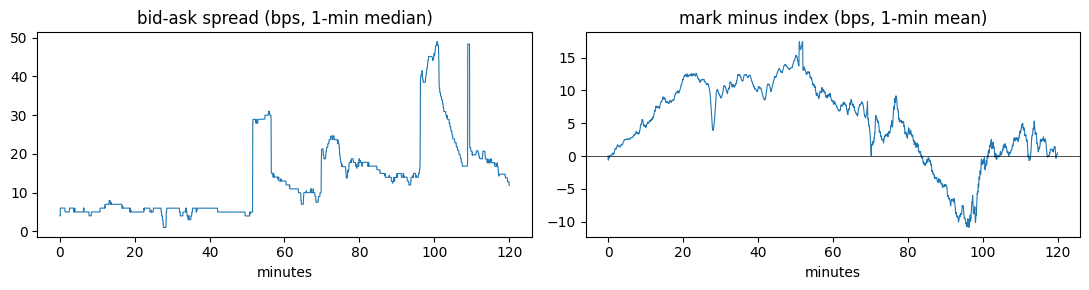

In [5]:
spread_bps = (bars["spread"] / bars["mid"] * 1e4).rolling(60, min_periods=1).median()
basis_bps = ((bars["mark"] / bars["index"] - 1) * 1e4).rolling(60, min_periods=1).mean()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3))
a.plot(minutes, spread_bps, lw=0.8); a.set_title("bid-ask spread (bps, 1-min median)"); a.set_xlabel("minutes")
b.plot(minutes, basis_bps, lw=0.8); b.axhline(0, color="k", lw=0.5); b.set_title("mark minus index (bps, 1-min mean)"); b.set_xlabel("minutes")
plt.tight_layout(); plt.show()

Basis arbitrageurs keep the perpetual close to the index, and the hourly
funding payment pushes it back when it drifts:

In [6]:
frames["funding"]

,time,rate,premium,mark_price,index_price,total_paid_by_longs
0,3600.0,9.395e-04,9.270e-04,100.200,100.154,5028.689
1,7200.0,1.207e-04,1.082e-04,101.385,101.339,256.750


## 3. Who made money

`group_table()` aggregates accounts by participant type; `agent_table()` has
one row per account, including path risk (drawdown, largest position,
highest leverage).

In [7]:
groups = pd.DataFrame(result.group_table()).set_index("agent_type")
groups[["agents", "return_pct", "median_return_pct", "total_pnl", "fees_paid", "volume", "maker_share", "liquidations"]]

,agents,return_pct,median_return_pct,total_pnl,fees_paid,volume,maker_share,liquidations
agent_type,,,,,,,,
informed,2,8.079,7.889,10712.789,1887.201,4.194e+06,0.000,0
whale,1,0.005,0.005,97.153,2711.813,7.161e+06,0.238,0
liquidation_hunter,1,0.000,0.000,0.000,0.000,0.000e+00,0.000,0
arbitrageur,4,-0.023,-0.096,-127.539,1132.980,2.518e+06,0.000,0
market_maker,3,-0.656,-0.397,-9802.392,8256.656,5.504e+07,1.000,0
retail,60,-2.934,-5.237,-12079.858,15813.782,3.799e+07,0.095,3
momentum,8,-4.820,-4.768,-19758.009,2787.960,6.195e+06,0.000,0
flow_follower,3,-6.191,-6.768,-4489.408,1741.539,3.870e+06,0.000,0
copy_trader,6,-7.092,-8.593,-5624.821,1848.221,4.107e+06,0.000,0


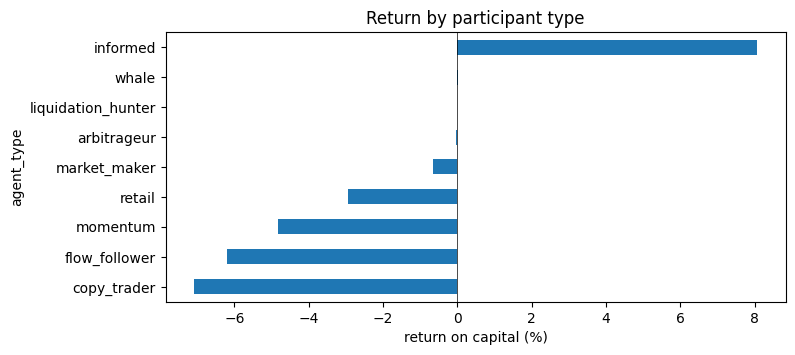

In [8]:
ax = groups["return_pct"].sort_values().plot.barh(figsize=(8, 3.5), color="tab:blue")
ax.axvline(0, color="k", lw=0.5); ax.set_xlabel("return on capital (%)"); ax.set_title("Return by participant type")
plt.show()

In [9]:
agents = pd.DataFrame(result.agent_table()).set_index("agent_id")
columns = ["agent_type", "initial_collateral", "total_pnl", "return_pct", "max_drawdown_pct", "max_leverage", "trade_count", "maker_share"]
pd.concat([agents.nlargest(5, "total_pnl"), agents.nsmallest(5, "total_pnl")])[columns]

,agent_type,initial_collateral,total_pnl,return_pct,max_drawdown_pct,max_leverage,trade_count,maker_share
agent_id,,,,,,,,
retail_31,retail,14403.320,11665.713,80.993,42.282,37.969,41,0.087
retail_51,retail,10553.708,7424.935,70.354,25.910,29.556,36,0.310
informed_01,informed,81832.988,7119.190,8.700,2.234,4.558,135,0.000
retail_11,retail,19706.647,4873.031,24.728,21.529,14.220,31,0.000
retail_29,retail,17026.065,4271.637,25.089,8.329,16.047,33,0.000
retail_27,retail,9902.462,-9902.462,-100.000,100.000,92.832,64,0.314
retail_21,retail,7470.842,-7470.842,-100.000,100.000,84.293,75,0.000
retail_06,retail,7330.940,-7330.940,-100.000,100.000,108.976,27,0.000
mm_01,market_maker,565261.722,-7173.713,-1.269,4.182,2.240,1557,1.000


The `equity` frame samples every account every 10 seconds. Here are the
market makers, the whale and the best and worst retail trader, as a fraction
of their starting capital:

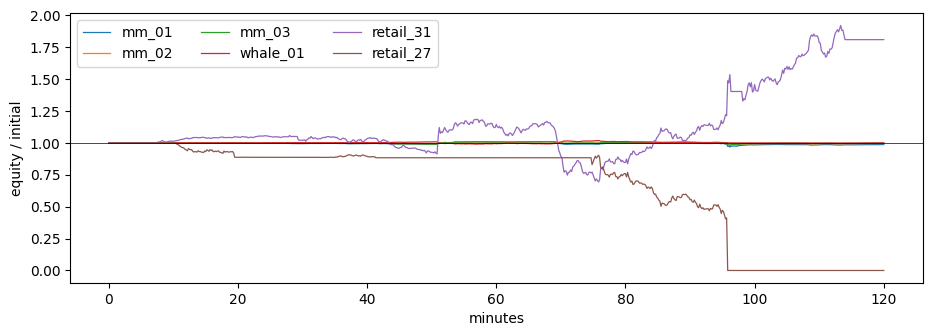

In [10]:
equity = frames["equity"]
retail = agents[agents["agent_type"] == "retail"]["total_pnl"]
chosen = ["mm_01", "mm_02", "mm_03", "whale_01", retail.idxmax(), retail.idxmin()]

fig, ax = plt.subplots()
for agent_id in chosen:
    ax.plot(equity.index / 60, equity[agent_id] / agents.loc[agent_id, "initial_collateral"], lw=0.9, label=agent_id)
ax.axhline(1, color="k", lw=0.5); ax.set_xlabel("minutes"); ax.set_ylabel("equity / initial"); ax.legend(ncol=3)
plt.show()

## 4. Statistical properties of returns

Real asset returns have *fat tails* (positive excess kurtosis) and
*volatility clustering* (large moves follow large moves, so absolute returns
are autocorrelated). `stylized_facts()` measures both at several horizons;
the scripted ecology reproduces them without being calibrated to do so.

In [11]:
facts = pd.DataFrame(result.stylized_facts()).T
facts[["n_returns", "std_bps", "excess_kurtosis", "acf_return_lag1", "acf_abs_return_lag1", "acf_abs_return_lag5"]]

,n_returns,std_bps,excess_kurtosis,acf_return_lag1,acf_abs_return_lag1,acf_abs_return_lag5
10s,720.0,14.301,26.197,-0.269,0.297,0.172
60s,120.0,27.923,14.207,0.045,0.398,-0.017
300s,24.0,42.632,0.479,0.166,0.085,0.190


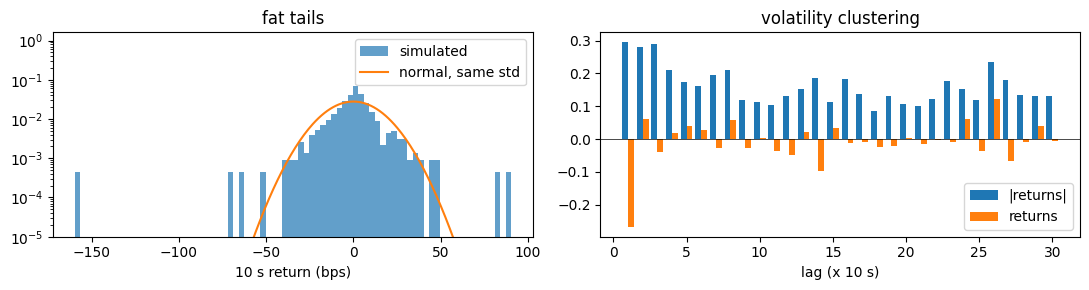

In [12]:
returns = np.log(bars["close"].ffill()).diff(10).iloc[10::10].dropna() * 1e4  # 10-second returns, bps
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3))
a.hist(returns, bins=80, density=True, alpha=0.7, label="simulated")
grid = np.linspace(returns.min(), returns.max(), 300)
a.plot(grid, np.exp(-0.5 * (grid / returns.std()) ** 2) / (returns.std() * np.sqrt(2 * np.pi)), label="normal, same std")
a.set_yscale("log"); a.set_ylim(bottom=1e-5); a.set_xlabel("10 s return (bps)"); a.legend(); a.set_title("fat tails")
lags = range(1, 31)
a_abs = [returns.abs().autocorr(lag) for lag in lags]
a_raw = [returns.autocorr(lag) for lag in lags]
b.bar([l - 0.2 for l in lags], a_abs, width=0.4, label="|returns|")
b.bar([l + 0.2 for l in lags], a_raw, width=0.4, label="returns")
b.axhline(0, color="k", lw=0.5); b.set_xlabel("lag (x 10 s)"); b.legend(); b.set_title("volatility clustering")
plt.tight_layout(); plt.show()

## 5. A volatile market: liquidations

The `volatile` scenario doubles index volatility and news. Highly leveraged
retail traders get liquidated: their position is closed by the exchange,
and if their margin does not cover the loss the insurance fund pays, then
auto-deleveraging (ADL) hits the most profitable opposite positions.

In [13]:
volatile = PerpetualMarket(scenarios.volatile(seed=2, duration=parse_duration("2h"))).run()
vframes = volatile.to_frames()
liq = vframes["liquidations"]
print(f"{len(liq)} liquidations, {volatile.summary()['liquidated_contracts']} contracts, bad debt {volatile.summary()['bad_debt']:.2f}")
liq.assign(liquidated=liq["side_closed"].map({"sell": "long", "buy": "short"}))[["time", "agent_id", "liquidated", "quantity", "mark_price", "equity_before", "penalty", "adl_quantity"]].head(8)

23 liquidations, 21060 contracts, bad debt 0.00


,time,agent_id,liquidated,quantity,mark_price,equity_before,penalty,adl_quantity
0,5240.415,retail_57,short,3283,102.753,4108.403,3373.373,0
1,6228.115,retail_58,short,294,103.411,374.449,304.029,0
2,6257.000,retail_27,short,458,103.640,578.407,474.671,0
3,6457.429,retail_45,short,502,104.310,654.511,465.212,0
4,6526.000,retail_59,short,734,105.215,958.468,772.279,0
5,6822.000,retail_10,short,181,106.403,212.288,192.589,0
6,6827.442,retail_17,short,1446,106.610,1878.322,1368.743,0
7,6828.000,retail_49,short,2108,106.950,2498.019,2165.862,0


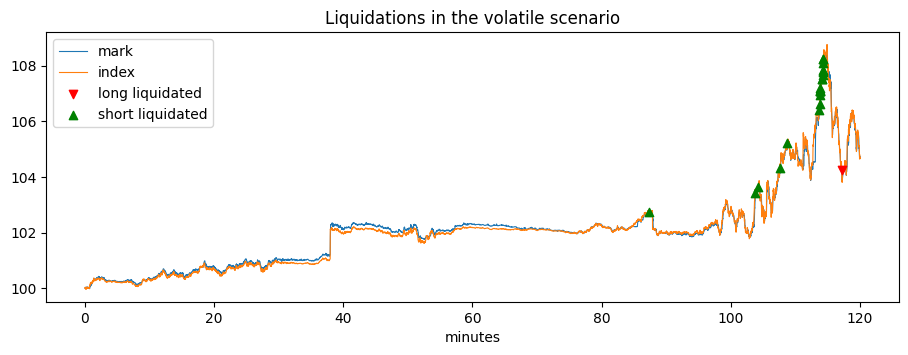

In [14]:
vbars = vframes["bars"]
fig, ax = plt.subplots()
ax.plot(vbars.index / 60, vbars["mark"], lw=0.8, label="mark")
ax.plot(vbars.index / 60, vbars["index"], lw=0.8, label="index")
longs = liq[liq["side_closed"] == "sell"]  # a long is closed by selling
shorts = liq[liq["side_closed"] == "buy"]
ax.scatter(longs["time"] / 60, longs["mark_price"], marker="v", color="red", zorder=3, label="long liquidated")
ax.scatter(shorts["time"] / 60, shorts["mark_price"], marker="^", color="green", zorder=3, label="short liquidated")
ax.set_xlabel("minutes"); ax.legend(); ax.set_title("Liquidations in the volatile scenario")
plt.show()

## 6. What agents can see: transparency

The transparency level is an experimental variable, enforced by each
agent's `MarketView`:

| level | agents see |
|---|---|
| `ANONYMOUS` | prices, the book (sizes only), trades without names |
| `ATTRIBUTED` | also who owns each order and who traded |
| `FULL` | also every account's position, leverage and liquidation price (as on Hyperliquid) |

Asking for more than the level allows raises `TransparencyError`. Here we
pause the same market at 5 minutes under each level and look through the
eyes of one retail trader:

In [15]:
for level in (Transparency.ANONYMOUS, Transparency.ATTRIBUTED, Transparency.FULL):
    market = PerpetualMarket(scenarios.default(seed=1, duration=600.0, transparency=level))
    market.run_until(300.0)
    view = market.view("retail_01")
    trade = view.recent_trades(1)[0]
    try:
        owners = {order.owner for order in view.book_orders(Side.BUY, depth=5)}
        book = f"bid owners {sorted(owners)}"
    except TransparencyError:
        book = "order owners hidden"
    try:
        positions = f"{len(view.accounts())} accounts with positions and liquidation prices"
    except TransparencyError:
        positions = "positions hidden"
    print(f"{level.value:10s} | last trade buyer={trade.buyer} | {book} | {positions}")

anonymous  | last trade buyer=None | order owners hidden | positions hidden
attributed | last trade buyer=0xe942…45f9 | bid owners ['0x2f0f…43c1', '0x3be8…73a5', '0x950a…4071', '0xb559…26bf', '0xe942…45f9', '0xf69e…aea6'] | positions hidden


full       | last trade buyer=0xb559…26bf | bid owners ['0x3be8…73a5', '0x950a…4071', '0xb559…26bf', '0xe942…45f9', '0xf69e…aea6'] | 87 accounts with positions and liquidation prices


In [16]:
# Under FULL, every account is public: this is what a liquidation hunter or a copy trader works with.
from dataclasses import asdict

accounts = pd.DataFrame([asdict(a) for a in view.accounts()])
accounts[accounts["position"] != 0].sort_values("leverage", ascending=False).head(8)

,public_id,position,entry_price,notional,equity,unrealized_pnl,leverage,liquidation_price,total_pnl,return_pct,active
9,0x1506…cfa4,-765,100.070,76512.120,2094.710,41.430,36.526,101.485,29.947,1.450,True
22,0x7e2a…a7ac,2383,100.056,238337.753,7268.811,-94.737,32.789,98.193,-202.031,-2.704,True
15,0x5daa…1153,-1282,100.044,128220.310,5411.710,35.730,23.693,102.950,-21.986,-0.405,True
47,0xb618…36b3,292,100.100,29204.626,1348.984,-24.574,21.649,96.604,-37.727,-2.721,True
26,0x8238…068c,1877,100.128,187729.737,9314.455,-211.183,20.155,96.257,-295.757,-3.078,True
6,0xc6bf…e42e,252,100.081,25203.992,1256.091,-16.418,20.065,96.234,-27.767,-2.163,True
14,0xcac4…5e76,-185,100.000,18502.931,998.634,-2.931,18.528,104.112,-11.256,-1.115,True
38,0xe9e9…e0b7,901,100.087,90114.274,4915.111,-64.486,18.334,95.758,-105.066,-2.093,True


The researcher always sees everything (`result`, the frames, the viewer);
the restriction applies only to what agents can use for their decisions.

## 7. Save, reload, replay, and the other tools

A run can be saved (text report, JSON summaries, CSV time series) and loaded
back for comparison without re-running it.

In [17]:
from glass_sim import Replay, SavedRun

path = result.save("runs/first_market")
saved = SavedRun.load(path)
print(sorted(p.name for p in path.iterdir()))
print(saved.summary["median_spread_bps"] == summary["median_spread_bps"])

['agents.json', 'bars.csv', 'equity.csv', 'funding.csv', 'groups.json', 'liquidations.csv', 'news.csv', 'positions.csv', 'replay.json', 'report.txt', 'stylized_facts.json', 'summary.json', 'trades.csv']
True


`replay.json` is the recipe of the run: the configuration, any agents added
by hand and every outside action, in a few kilobytes. Because GLASS is
deterministic, replaying it rebuilds the market exactly, with the full order
book and every account at any moment, and checks the result against the
original:

In [18]:
replay = Replay.load(path)
print(replay.describe(), f"({(path / 'replay.json').stat().st_size / 1024:.1f} KB)")
replay.verify(replay.run())

default seed 1, full, 2.00 h (5.5 KB)


{'identical': True,
 'differences': {},
 'recorded_with': '0.1.0',
 'replayed_with': '0.1.0'}

To watch it in the viewer, with a timeline you can click to jump to any
moment: `glass serve --replay runs/first_market`. Share the directory (or
just `replay.json`) and anyone with GLASS can open the same run.

In [19]:
print(result.report()[:1500])

Scenario default  seed 1  transparency full  duration 2.00h

Activity
  Trades                         4,709
  Volume (contracts)             602,131
  Trades per minute              39.2
  Mean open interest             37,493
  Max open interest              59,829

Liquidity
  Two-sided book (fraction)      0.9999
  Median spread (bps)            10.94
  Mean spread (price)            0.1413
  Mean bid depth <=50 ticks      7,516
  Mean ask depth <=50 ticks      4,786

Prices
  1-minute return vol (bps)      27.92
  |last - index| mean (bps)      10.56
  |last - index| max (bps)       92.2
  |mark - index| mean (bps)      7.11
  Final last price               101.440
  Final mark price               101.385
  Final index price              101.339

Risk and funding
  Liquidations                   3
  Liquidated contracts           6,054
  Auto-deleveraged contracts     2,414
  Bad debt                       0.00
  Insurance fund (final)         254,891.93
  Funding settlements     

From the command line:

```bash
glass scenarios                                         # list scenarios
glass run --scenario volatile --seed 2 --duration 2h --agents
glass compare "scenario=default" "scenario=anonymous" --seeds 1-10
glass serve --scenario default --seed 1 --open          # live viewer in the browser
glass replay runs/first_market                          # re-run a saved run and check it
```

**Next**: [2. Agents and experiments](02_agents_and_experiments.ipynb), where
you write your own trader and run a controlled experiment.